In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [9]:
untargeted_lipidomics_df = pd.read_excel("~/Horse_Metabolomics_26/Heather_Knych_lipidomics_horse_serum_urine_02-2025_submit.xlsx", sheet_name = ["Urine data", "Serum data", "Urine internal standards", "Serum internal standards"])
targeted_met_lipids_serum_df = pd.read_excel("~/Horse_Metabolomics_26/mx_843346_Knych_horse_serum_MXP500_01-2025_submit.xlsx", sheet_name = "Data")
targeted_met_lipids_urine_df = pd.read_excel("~/Horse_Metabolomics_26/mx_843346_Knych_horse_urine_MXP500_01-2025_submit.xlsx", sheet_name = "Data")
untargeted_metabolomics_df = pd.read_excel("~/Horse_Metabolomics_26/mx_844156,_Heather_Knych_equine_serum_and_urine_primary_metabolism_GC-TOF_MS_10-2024_submit.xlsx", sheet_name = "submit")

In [10]:
untargeted_lipidomics_df["Urine data"].head(10)

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Label,Frankie 1.29.2032,Spork 1.29.2024,Charlie 1.29.2029,S2207326,S2208680,S2209415,S2209728,S2301257,Spagurter 1.29.2030,Dan 1.29.2028,MtdBlank001,PoolQC001
0,NaN,NaN,NaN,NaN,NaN,NaN,Sample #,30,31,32,33,34,35,36,37,38,40,Blank,Pool
1,NaN,NaN,NaN,NaN,NaN,NaN,Species,equine,equine,equine,equine,equine,equine,equine,equine,equine,equine,NaN,equine
2,NaN,NaN,NaN,NaN,NaN,NaN,Organ,urine,Urine,Urine,Urine,Urine,Urine,Urine,Urine,Urine,Urine,NaN,urine
3,NaN,NaN,NaN,NaN,NaN,NaN,Treatment,control,control,control,Sudden death,Sudden death,Sudden death,Sudden death,Sudden death,control,control,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,Subtreatment,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,File ID,Knych0010_MX843469_posLIPIDS_Frankie-1-29-2024...,Knych0002_MX843469_posLIPIDS_Spork-1-29-2024-0...,Knych0007_MX843469_posLIPIDS_Charlie-1-29-2024...,Knych0003_MX843469_posLIPIDS_S2207326-033.raw,Knych0005_MX843469_posLIPIDS_S2208680-034.raw,Knych0001_MX843469_posLIPIDS_S2209415-035.raw,Knych0009_MX843469_posLIPIDS_S2209728-036.raw,Knych0004_MX843469_posLIPIDS_S2301257-037.raw,Knych0008_MX843469_posLIPIDS_Spagurter-1-29-20...,Knych0006_MX843469_posLIPIDS_Dan-1-29-2024-040...,MtdBlank001_MX843469_posLIPIDS_preKnych0001.raw,PoolQC001_MX843469_posLIPIDS_preKnych0001.raw
6,NaN,NaN,NaN,NaN,NaN,NaN,File ID,Knych0010_MX843469_negLIPIDS_Frankie-1-29-2024...,Knych0002_MX843469_negLIPIDS_Spork-1-29-2024-0...,Knych0007_MX843469_negLIPIDS_Charlie-1-29-2024...,Knych0003_MX843469_negLIPIDS_S2207326-033.raw,Knych0005_MX843469_negLIPIDS_S2208680-034.raw,Knych0001_MX843469_negLIPIDS_S2209415-035.raw,Knych0009_MX843469_negLIPIDS_S2209728-036.raw,Knych0004_MX843469_negLIPIDS_S2301257-037.raw,Knych0008_MX843469_negLIPIDS_Spagurter-1-29-20...,Knych0006_MX843469_negLIPIDS_Dan-1-29-2024-040...,MtdBlank001_MX843469_negLIPIDS_preKnych0001.raw,PoolQC001_MX843469_negLIPIDS_preKnych0001.raw
7,identifier,annotation,ion species,InChI Key,m/z,ret.time (min),ESI mode,Peak Height,Peak Height,Peak Height,Peak Height,Peak Height,Peak Height,Peak Height,Peak Height,Peak Height,Peak Height,Peak Height,Peak Height
8,1.93_861.55,"1,2-Dioleoyl-sn-glycero-3-phospho-(1'-myo-inos...",[M-H]-,LALGUHSIWLNTNW-UHFFFAOYSA-N,861.5491,1.925,ESI neg,15834,8702,21875,1757058,950397,8775,3825044,21689,20278,221791,NaN,356981
9,0.26_319.23,12-HETE,[M-H]-,ZNHVWPKMFKADKW-LQWMCKPYSA-N,319.2277,0.261,ESI neg,24072,13738,3955,83528,874525,6655,974495,4214,7017,65054,2438,112108


In [8]:
Organ_Type = "Urine"

df = pd.read_excel("Documents/BrownLab/knych_mxp500/Primary_Metabolism_Clean.xlsx", sheet_name=Organ_Type, skiprows=2)

# Remove unwanted columns
df_Serum = df.drop(columns=["Urine_Percent", "Serum_Percent"])

# Transpose
df_Serum = df_Serum.T

# Use the first row as the column headers
df_Serum.columns = df_Serum.iloc[0]
df_Serum = df_Serum.iloc[1:].reset_index()

# Rename the transposed index column
df_Serum = df_Serum.rename(columns={"index": "Samples", "Variable": "Samples"})

# Create Type based on the sample name
df_Serum["Type"] = np.where(
    df_Serum["Samples"].str.contains("Control", case=False, na=False),
    "Control",
    "Case"
)

df_Serum.insert(
    1,
    "Type",
    df_Serum.pop("Type")
)

FileNotFoundError: [Errno 2] No such file or directory: 'Documents/BrownLab/knych_mxp500/Primary_Metabolism_Clean.xlsx'

In [ ]:
df_Serum

Variable,Samples,Type,zymosterol,xylulose,xylose,xylonic acid,xylitol,x-methyladenosine,xanthurenic acid,xanthosine,...,4879,14684,21709,89050,88992,171564,88981,106498,376650,131621
0,Control_Urine_1,Control,163,6060,20211,1195,15382,450,893,76,...,90,117169,2141,470,14,5670,269,133015,397,11800
1,Control_Urine_2,Control,58,5212,19243,1107,11336,466,663,112,...,65,9734,3618,1126,122,4478,132,1667,820,15570
2,Control_Urine_3,Control,203,7100,25642,1374,24223,686,1407,58,...,47,186006,3296,1079,214,9468,337,5112,381,11981
3,Control_Urine_4,Control,200,5990,25239,629,16168,699,695,115,...,95,104740,1345,1114,214,6169,238,98836,697,35362
4,Control_Urine_5,Control,160,5232,21248,1777,12897,609,734,92,...,124,62648,3098,735,150,6200,138,11877,510,22785
5,Case_Urine_1,Case,538,17105,84254,681,41522,1664,2013,103,...,96,7282,678,509,132,58963,288,801,290,6883
6,Case_Urine_2,Case,188,16323,79350,975,37219,1422,3000,68,...,307,9111,521,576,62,296485,388,222338,1008,1423
7,Case_Urine_3,Case,269,24667,86244,1034,83145,1527,4527,107,...,1953,88729,263,1306,17,85232,528,5339,294,674
8,Case_Urine_4,Case,128,21518,80941,1568,51284,1347,3181,111,...,84,4360,331,849,34,78585,357,140270,200,2127
9,Case_Urine_5,Case,161,8745,55966,975,29285,922,1935,49,...,113,94891,34223,640,71,22519,243,37580,568,2072


In [ ]:
# Convert all measurement columns to numeric
sample_names = df_Serum["Samples"]
groups = df_Serum["Type"]

# Keep all columns except the sample and group columns
X = df_Serum.drop(columns=["Samples", "Type"])

#X = X.apply(pd.to_numeric, errors="coerce")
X.columns = X.columns.astype(str)

print("Number of samples:", X.shape[0])
print("Number of variables:", X.shape[1])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#X.describe()

Number of samples: 10
Number of variables: 1250


In [ ]:
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    principal_components,
    columns=["PC1", "PC2"]
)

pca_df["Sample"] = sample_names.values
pca_df["Group"] = groups.values

pca_df.head()

,PC1,PC2,Sample,Group
0,-19.583641,1.907781,Control_Urine_1,Control
1,-22.480270,-2.092851,Control_Urine_2,Control
2,-16.030499,-5.415691,Control_Urine_3,Control
3,-19.276057,-0.788415,Control_Urine_4,Control
4,-19.531350,-0.469249,Control_Urine_5,Control


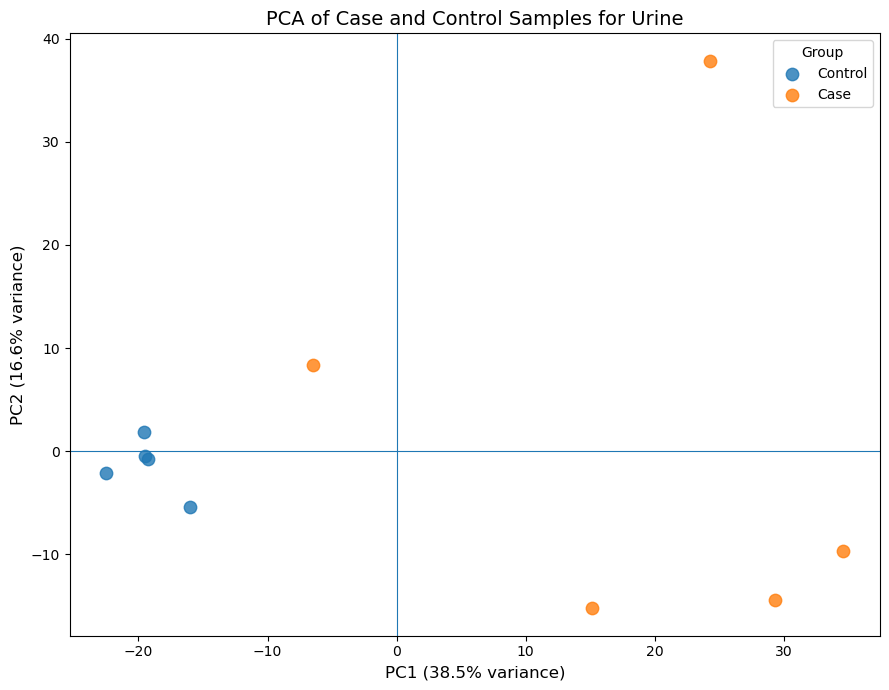

In [ ]:
pc1_variance = pca.explained_variance_ratio_[0] * 100
pc2_variance = pca.explained_variance_ratio_[1] * 100

fig, ax = plt.subplots(figsize=(9, 7))

for group in pca_df["Group"].unique():
    subset = pca_df[pca_df["Group"] == group]
    ax.scatter(
        subset["PC1"],
        subset["PC2"],
        s=80,
        alpha=0.8,
        label=group
    )

ax.axhline(0, linewidth=0.8)
ax.axvline(0, linewidth=0.8)

ax.set_xlabel(f"PC1 ({pc1_variance:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2 ({pc2_variance:.1f}% variance)", fontsize=12)
ax.set_title(f"PCA of Case and Control Samples for {Organ_Type}", fontsize=14)
ax.legend(title="Group")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.multitest import multipletests

# Exclude sample metadata
variables = df_Serum.columns.difference(["Samples", "Type"])

results = []

for variable in variables:

    control = pd.to_numeric(
        df_Serum.loc[df_Serum["Type"] == "Control", variable],
        errors="coerce"
    ).dropna()

    case = pd.to_numeric(
        df_Serum.loc[df_Serum["Type"] == "Case", variable],
        errors="coerce"
    ).dropna()

    # Welch's independent t-test
    t_stat, p_val = stats.ttest_ind(
        control,
        case,
        equal_var=False
    )

    results.append({
        "Variable": variable,
        "Control_Mean": control.mean(),
        "Case_Mean": case.mean(),
        "Mean_Difference": case.mean() - control.mean(),
        "T_Statistic": t_stat,
        "P_Value": p_val
    })

t_test_results = pd.DataFrame(results)

In [ ]:
t_test_results.to_csv(f"Documents/BrownLab/knych_mxp500/Primary_Metabolism_{Organ_Type}_T-TestResults.csv")